This file is for testing the analytical solutions of the Black-Scholes equation implemented in analytical.py.

In [1]:
import sys
import os

sys.path.append(os.path.abspath(".."))

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

from src.analytical import call_price, black_scholes_call_grid

In [2]:
# Test a single Black-Scholes call price

call = call_price(S0=100, tau=1.0, K=100, r=0.05, sigma=0.2)

print(call)

10.450583572185565


In [3]:
# Basic checks on the analytical call price function

S = np.array([80, 100, 120])
tau = np.array([0.0, 0.0, 0.0])

expiry_prices = call_price(S0=S, tau=tau, K=100, r=0.05, sigma=0.2)
expected_payoff = np.maximum(S - 100, 0.0)

np.allclose(expiry_prices, expected_payoff)

True

In [4]:
# Check that the grid wrapper gives the same result as call_price

S_test = np.linspace(50, 150, 10)
tau_test = np.linspace(0.01, 1.0, 10)

S_grid, tau_grid = np.meshgrid(S_test, tau_test)

direct_prices = call_price(S0=S_grid, tau=tau_grid, K=100, r=0.05, sigma=0.2)
grid_prices = black_scholes_call_grid(S0=S_grid, tau=tau_grid, K=100, r=0.05, sigma=0.2)

np.allclose(direct_prices, grid_prices)

True

In [5]:
# Generating a call-price surface

S_values = np.linspace(50, 150, 100)
tau_values = np.linspace(0.01, 2.0, 100)

S_grid, tau_grid = np.meshgrid(S_values, tau_values)

C_grid = call_price(S0=S_grid, tau=tau_grid, K=100, r=0.05, sigma=0.2)

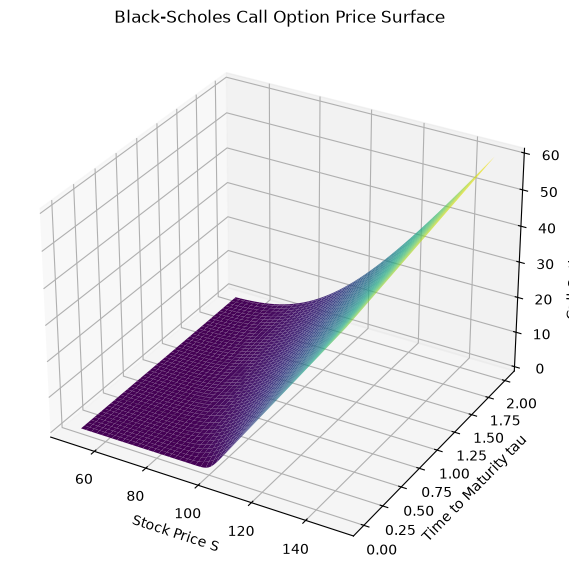

In [6]:
# Plotting the call-price surface

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(S_grid, tau_grid, C_grid, cmap="viridis")

ax.set_xlabel("Stock Price S")
ax.set_ylabel("Time to Maturity tau")
ax.set_zlabel("Call Option Price C")
ax.set_title("Black-Scholes Call Option Price Surface")

plt.show()